In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from utils import evaluate

close = pd.read_csv("../data/raw_close_prices.csv", index_col=0, parse_dates=True)
close = close.dropna(subset=["MSFT"]).ffill(limit=3).dropna()
weekly_close = close.resample("W-FRI").last()
if close.index[-1] < weekly_close.index[-1]:
    weekly_close = weekly_close.iloc[:-1]
weekly_ret = weekly_close.pct_change().dropna()

lags = [0, 1, 2, 3, 4]
features = pd.concat([weekly_ret.shift(l).add_suffix(f"_lag{l}") for l in lags], axis=1, sort=False)
print("Latest complete week:", weekly_ret.index[-1].date())

def make_xy(ticker):
    target = weekly_ret[ticker].shift(-1)
    d = pd.concat([features, target.rename("y")], axis=1, sort=False).dropna()
    return d.drop(columns="y"), d["y"]

Latest complete week: 2026-10-23


In [2]:
param_dist = {
    "n_estimators": [100, 200, 300], "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.02, 0.05], "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0], "min_child_weight": [1, 5, 10, 20],
    "reg_lambda": [1, 10, 50, 100],
}

def ridge_search():
    return GridSearchCV(
        Pipeline([("s", StandardScaler()), ("r", Ridge())]),
        {"r__alpha": np.logspace(-1, 4, 20)},
        cv=TimeSeriesSplit(n_splits=5), scoring="neg_root_mean_squared_error")

def xgb_search():
    return RandomizedSearchCV(
        XGBRegressor(random_state=42, n_jobs=1), param_dist, n_iter=15,
        cv=TimeSeriesSplit(n_splits=3), scoring="neg_root_mean_squared_error",
        random_state=42, n_jobs=1)

makers = {"Ridge": ridge_search, "XGBoost (tuned)": xgb_search}

rows, forecasts = [], []
x_next = features.iloc[[-1]]          # latest complete week: features known today

for ticker in ["MSFT", "IBM", "GOOGL"]:
    X, y = make_xy(ticker)
    split = int(len(X) * 0.8)
    X_tr, X_te, y_tr, y_te = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
    mu = y_tr.mean()

    for name, mk in makers.items():
        s = mk().fit(X_tr, y_tr)                      # tune and fit on training only
        rows.append({**evaluate(y_te, s.predict(X_te), mu, name), "stock": ticker})

        full = mk().fit(X, y)                         # refit on everything for the forecast
        pred = float(full.predict(x_next)[0])
        forecasts.append({
            "stock": ticker, "model": name,
            "expected_weekly_return": pred,
            "annualized_approx": pred * 52,
            "historical_mean_weekly": y.mean(),
        })
        print(ticker, name, "done", flush=True)

metrics = pd.DataFrame(rows).set_index(["stock", "model"])
fc = pd.DataFrame(forecasts).set_index(["stock", "model"])
print(metrics.round(4))
print((fc * 100).round(3).assign(note="values in %"))

MSFT Ridge done
MSFT XGBoost (tuned) done
IBM Ridge done
IBM XGBoost (tuned) done
GOOGL Ridge done
GOOGL XGBoost (tuned) done
                         RMSE     MAE      R2  R2_OOS  DirAcc
stock model                                                  
MSFT  Ridge            0.0366  0.0260  0.0060  0.0072  0.5086
      XGBoost (tuned)  0.0366  0.0261  0.0059  0.0071  0.5429
IBM   Ridge            0.0468  0.0316 -0.0086 -0.0017  0.5371
      XGBoost (tuned)  0.0469  0.0317 -0.0117 -0.0049  0.5257
GOOGL Ridge            0.0429  0.0330 -0.0043 -0.0008  0.5600
      XGBoost (tuned)  0.0429  0.0331 -0.0077 -0.0042  0.5314
                       expected_weekly_return  annualized_approx  \
stock model                                                        
MSFT  Ridge                             0.384             19.964   
      XGBoost (tuned)                   0.508             26.418   
IBM   Ridge                             0.184              9.589   
      XGBoost (tuned)                 

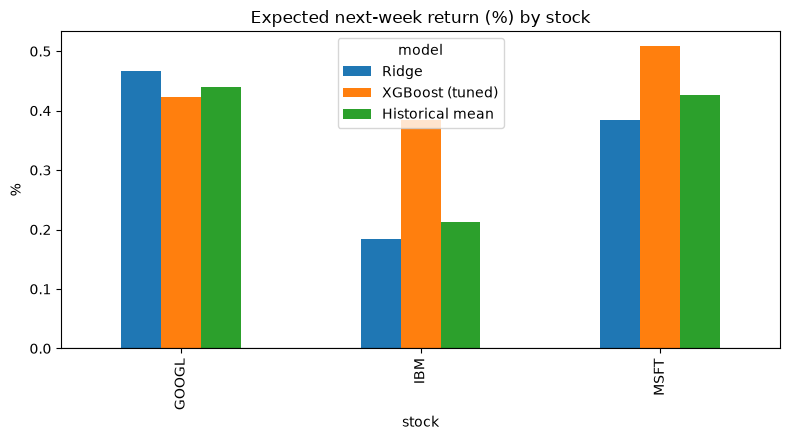

In [3]:
import os
os.makedirs("../results", exist_ok=True)
metrics.to_csv("../results/multi_stock_metrics.csv")
fc.to_csv("../results/expected_returns.csv")

p = (fc["expected_weekly_return"] * 100).unstack()
p["Historical mean"] = (fc["historical_mean_weekly"].groupby(level=0).first() * 100)
p.plot.bar(figsize=(8, 4.5), title="Expected next-week return (%) by stock")
plt.axhline(0, color="k", lw=0.8)
plt.ylabel("%"); plt.tight_layout()
plt.savefig("../figures/20_expected_returns.png", dpi=150)
plt.show()

In [1]:
import os
import pandas as pd

needed = ["expected_returns.csv", "deep_expected_returns.csv",
          "multi_stock_metrics.csv", "deep_multi_stock_metrics.csv"]
for f in needed:
    print(f, os.path.exists(f"../results/{f}"))

a = pd.read_csv("../results/expected_returns.csv", index_col=[0, 1])
b = pd.read_csv("../results/deep_expected_returns.csv", index_col=[0, 1])
allfc = pd.concat([a, b]).sort_index()
print((allfc[["expected_weekly_return", "historical_mean_weekly"]] * 100).round(3))
allfc.to_csv("../results/expected_returns_all_frameworks.csv")

m1 = pd.read_csv("../results/multi_stock_metrics.csv", index_col=[0, 1])
m2 = pd.read_csv("../results/deep_multi_stock_metrics.csv", index_col=[0, 1])
pd.concat([m1, m2]).sort_index().round(4).to_csv("../results/multi_stock_metrics_all.csv")
print("saved")

expected_returns.csv True
deep_expected_returns.csv True
multi_stock_metrics.csv True
deep_multi_stock_metrics.csv True
                       expected_weekly_return  historical_mean_weekly
stock model                                                          
GOOGL Keras MLP                         1.054                   0.440
      Lightning MLP                     0.636                   0.440
      Ridge                             0.466                   0.440
      TabNet                            0.174                   0.440
      XGBoost (tuned)                   0.422                   0.440
      fastai tabular                    0.989                   0.440
IBM   Keras MLP                         0.699                   0.213
      Lightning MLP                     0.385                   0.213
      Ridge                             0.184                   0.213
      TabNet                           -0.463                   0.213
      XGBoost (tuned)                   